# 05 — Validate speed and observed acceleration profiles within position groups

This notebook validates the **all-position Combine comparison**, not only the 43-WR NFL pilot. Include DB, DL, OL, TE, and WR players, preserving everyone in the comparison roster. Evaluate observed peak magnitude, observed peak timing, and speed-building intervals. Calculate repeatability within position groups and show draft-year sensitivity; do not inflate correlations by pooling linemen and receivers.

Repeated-attempt checks require two measured recordings for that feature. They do not remove single-recording players from the main comparison. Agreement between attempts reflects execution plus measurement differences; it is not a pure sensor-error estimate or proof of an intrinsic athlete trait. Observed peak timing is never relabeled as confirmed time from physical launch.

The original NFL model/results are preserved in `archive/05_wr_nfl_validation_pilot.ipynb` and `outputs/validation/`. Notebook 04 still contains that WR-specific outcome definition. Section F explicitly reports that the new position-specific NFL stage needs a broader Notebook 04 handoff; this notebook does not silently apply the WR route outcome to other positions.


## A. Load the all-position profiles and check provenance

Run Notebook 02 through Section F and the main Notebook 03 completely before this notebook. No shared kernel variables, API login, or NFL tracking scan is needed for the Combine validation. Inputs are checked against their manifests; if preparation was rerun, rerun Notebook 03 to refresh the linked profile handoff.


In [1]:
from pathlib import Path
import hashlib
import importlib
import json
import sys
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents]
           if (p/"scripts/validate_profiles.py").is_file()),None)

if ROOT is None:
    raise FileNotFoundError("Open the project folder containing scripts/validate_profiles.py")

PROFILES=ROOT/"outputs/all_position_profiles"
PREPARED=ROOT/"outputs/prepared_all_positions"
OUTPUT=ROOT/"outputs/all_position_validation"
OUTPUT.mkdir(parents=True,exist_ok=True)

def verified_manifest(folder):
    path=folder/"manifest.json"
    
    if not path.is_file():
        raise FileNotFoundError(f"Missing handoff: {path}. Run Notebooks 02 and 03 first.")
    
    manifest=json.loads(path.read_text())
    
    if manifest.get("schema_version")!=1:
        raise ValueError(f"Unsupported handoff version: {folder}")
    
    for name,info in manifest["files"].items():
        
        if hashlib.sha256((folder/name).read_bytes()).hexdigest()!=info["sha256"]:
            raise ValueError(f"Changed handoff file: {folder/name}; regenerate the source notebook export")
    
    return manifest

prepared_manifest=verified_manifest(PREPARED)
profile_manifest=verified_manifest(PROFILES)

if profile_manifest["source_all_position_manifest_sha256"]!=hashlib.sha256((PREPARED/"manifest.json").read_bytes()).hexdigest():
    raise ValueError("Notebook 02 changed after the profile export. Rerun Notebook 03 before Notebook 05.")

GROUP_COLS=prepared_manifest["group_columns"]

identifier_types={column:"string" for column in GROUP_COLS}

def read_table(folder,name,manifest):
    table=pd.read_csv(folder/name,dtype=identifier_types)
    
    if len(table)!=manifest["files"][name]["rows"]:
        raise ValueError(f"Row count differs from manifest: {name}")
    
    return table

roster=read_table(PROFILES,"comparison_roster.csv",profile_manifest)
peaks=read_table(PROFILES,"observed_peak_profiles.csv",profile_manifest)
intervals=read_table(PROFILES,"all_position_speed_intervals.csv",profile_manifest)

frames=read_table(PREPARED,"all_forty_frames.csv",prepared_manifest)
frames["time"]=pd.to_datetime(frames["time"],errors="raise")

flag=roster["discrepancy_review"].astype("string").str.lower().map({"true":True,"false":False})

if flag.isna().any():
    raise ValueError("Missing or unrecognized discrepancy-review flag")

roster["discrepancy_review"]=flag.astype(bool)

if roster.duplicated("nfl_id").any() or frames.duplicated(GROUP_COLS+["time"]).any():
    raise ValueError("Duplicate player identity or recording timestamps")

roster["official_forty_hundredths"]=pd.to_numeric(roster["official_forty_hundredths"],errors="coerce").astype("Int64")

if str(ROOT/"scripts") not in sys.path:
    sys.path.insert(0,str(ROOT/"scripts"))

import player_comparison
import validate_profiles

importlib.reload(player_comparison)
importlib.reload(validate_profiles)

print("All-position comparison roster:",len(roster),"players")

roster_coverage=roster.groupby("combine_position").agg(
    players=("nfl_id","size"),recordings=("recordings","sum"),
    players_with_one_recording=("recordings",lambda s:int(s.eq(1).sum())),
    players_with_two_recordings=("recordings",lambda s:int(s.eq(2).sum())))

display(roster_coverage)

All-position comparison roster: 418 players


,players,recordings,players_with_one_recording,players_with_two_recordings
combine_position,,,,
DB,102,195,9,93
DL,93,177,9,84
OL,95,179,11,84
TE,34,66,2,32
WR,94,176,12,82


## B. Validate peak timing references without inventing launch times

Keep two separate timing features: (1) seconds from the first recorded frame and (2) seconds relative to the observed, sustained 3-unit speed crossing used by the comparison controls. The latter reduces dependence on extra recording time before speed buildup, but it is **not physical launch**. A peak before the crossing can legitimately have a negative relative time. Neither reference recovers an unobserved peak.

If the speed reference is not bracketed and supported, leave that timing unavailable. Magnitude and recording-relative timing stay available when otherwise measured. Keep the 5/7/9-frame settings rather than selecting a favorable window. Raw and smoothed interval settings also remain separate. Percentage agreement is not reported for timing features, whose reference can be near zero or negative.


In [2]:
reference_rows=[]

for key,group in frames.groupby(GROUP_COLS,dropna=False,sort=False):
    record=dict(zip(GROUP_COLS,key))
    
    try:
        curve=player_comparison.attempt_curve(group,7)
        reference=player_comparison.speed_reference(curve["t"],curve["speed"],threshold=3.0)
        record.update(reference_status="Measured",reference_time_s=reference)
    
    except ValueError as exc:
        record.update(reference_status="Unavailable",reference_time_s=np.nan,reference_reason=str(exc))
    
    reference_rows.append(record)

references=pd.DataFrame(reference_rows)
feature_values=validate_profiles.profile_feature_table(peaks,intervals,references,roster,GROUP_COLS)

print("Observed 3-unit reference availability:")
display(references["reference_status"].value_counts().to_frame("recordings"))
print("Feature status by position (including unsupported values):")

feature_coverage=feature_values.groupby(["combine_position","feature","method","status"],dropna=False).size().rename("recordings").reset_index()

primary_methods=feature_coverage["method"].eq("Raw")|(
    feature_coverage["method"].eq("7-frame")&feature_coverage["feature"].str.startswith("peak_"))

display(feature_coverage.loc[primary_methods])

Observed 3-unit reference availability:


,recordings
reference_status,
Measured,792
Unavailable,1


Feature status by position (including unsupported values):


,combine_position,feature,method,status,recordings
1,DB,peak_magnitude,7-frame,Measured,195
4,DB,peak_time_recording_start_s,7-frame,Measured,195
7,DB,peak_time_speed3_reference_s,7-frame,Measured,195
16,DB,speed_interval_2_to_4_s,Raw,Measured,195
22,DB,speed_interval_3_to_7_s,Raw,Measured,195
27,DB,speed_interval_4_to_6_s,Raw,Measured,195
31,DB,speed_interval_6_to_8_s,Raw,Measured,195
35,DB,speed_interval_8_to_10_s,Raw,Measured,195
37,DL,peak_magnitude,7-frame,Measured,177
40,DL,peak_time_recording_start_s,7-frame,Measured,177


## C. Check repeated-attempt agreement within each position

Use players with exactly two available recordings and two measured values for a feature/method. Keep their two attempts together. Report ranking correlations and absolute differences; one does not replace the other. A/B follows the reported attempt label, not verified chronological order. Report all measured pairs plus an interior-peak sensitivity subset; never delete boundary cases silently.

The descriptive bootstrap resamples **players within draft year**, preserving the observed year counts, and estimates an interval for median absolute paired difference. It conditions on these measured recordings and is not an independent-test guarantee, a refit of measurement processing, or an estimate of pure tracking noise. Cross-year processing differences may remain. Do not choose methods, discard players, or promote a feature solely because a result looks better.

Bootstrap intervals are left unavailable for fewer than five paired players. All pair counts remain visible; year-specific tables omit bootstrap intervals.


In [3]:
BOOTSTRAPS = 2000

paired_features=validate_profiles.pair_features(feature_values,GROUP_COLS)

repeatability=validate_profiles.summarize_pairs(feature_values,paired_features,bootstraps=BOOTSTRAPS,seed=2026)
year_repeatability=validate_profiles.summarize_pairs(feature_values,paired_features,by_year=True,bootstraps=0)

primary_summary=repeatability.loc[
    repeatability["scope"].eq("All measured pairs") & (
        (repeatability["method"].eq("7-frame")&repeatability["feature"].str.startswith("peak_"))
        | repeatability["method"].eq("Raw"))
].copy()

summary_columns=["combine_position","feature","method","unit","paired_players","pearson","spearman",
                 "median_absolute_difference","conditional_median_ad_p025","conditional_median_ad_p975"]

print("7-frame observed peaks and timing references:")
display(primary_summary.loc[primary_summary["feature"].str.startswith("peak_"),summary_columns].round(4))

print("Raw speed-band durations:")
display(primary_summary.loc[~primary_summary["feature"].str.startswith("peak_"),summary_columns].round(4))

print("No player is removed from the comparison roster for lacking a pair or a supported interval.")

7-frame observed peaks and timing references:


,combine_position,feature,method,unit,paired_players,pearson,spearman,median_absolute_difference,conditional_median_ad_p025,conditional_median_ad_p975
2,DB,peak_magnitude,7-frame,raw speed units / s,93,0.3310,0.3743,0.3250,0.2631,0.4119
8,DB,peak_time_recording_start_s,7-frame,seconds,93,0.1246,0.3856,0.1000,0.1000,0.1000
14,DB,peak_time_speed3_reference_s,7-frame,seconds,93,0.5127,0.4291,0.0623,0.0447,0.0718
40,DL,peak_magnitude,7-frame,raw speed units / s,84,0.6557,0.6930,0.2722,0.2064,0.3515
46,DL,peak_time_recording_start_s,7-frame,seconds,84,0.5845,0.5587,0.1000,0.1000,0.1000
52,DL,peak_time_speed3_reference_s,7-frame,seconds,84,0.5864,0.5748,0.0607,0.0430,0.0793
78,OL,peak_magnitude,7-frame,raw speed units / s,84,0.5810,0.5215,0.3337,0.2726,0.4095
84,OL,peak_time_recording_start_s,7-frame,seconds,84,0.5519,0.4228,0.1000,0.1000,0.2000
90,OL,peak_time_speed3_reference_s,7-frame,seconds,84,0.4761,0.4453,0.0610,0.0521,0.0738
116,TE,peak_magnitude,7-frame,raw speed units / s,32,0.3038,0.3057,0.3506,0.2035,0.4493


Raw speed-band durations:


,combine_position,feature,method,unit,paired_players,pearson,spearman,median_absolute_difference,conditional_median_ad_p025,conditional_median_ad_p975
21,DB,speed_interval_2_to_4_s,Raw,seconds,93,0.3669,0.4183,0.0254,0.0185,0.0305
25,DB,speed_interval_3_to_7_s,Raw,seconds,93,0.4547,0.4875,0.0488,0.0418,0.0614
29,DB,speed_interval_4_to_6_s,Raw,seconds,93,0.4217,0.4558,0.0237,0.0193,0.0292
33,DB,speed_interval_6_to_8_s,Raw,seconds,93,0.7042,0.6665,0.0365,0.0285,0.0416
37,DB,speed_interval_8_to_10_s,Raw,seconds,93,0.8280,0.8081,0.0846,0.0634,0.1187
59,DL,speed_interval_2_to_4_s,Raw,seconds,84,0.6506,0.6448,0.0264,0.0170,0.0335
63,DL,speed_interval_3_to_7_s,Raw,seconds,84,0.8365,0.8316,0.0490,0.0361,0.0603
67,DL,speed_interval_4_to_6_s,Raw,seconds,84,0.7859,0.8054,0.0239,0.0189,0.0296
71,DL,speed_interval_6_to_8_s,Raw,seconds,84,0.9222,0.8833,0.0467,0.0430,0.0612
75,DL,speed_interval_8_to_10_s,Raw,seconds,39,0.7802,0.7723,0.1366,0.0900,0.1984


No player is removed from the comparison roster for lacking a pair or a supported interval.


## D. Inspect agreement and year sensitivity

Timing in the second and third panels uses seconds; the magnitude panel retains raw speed units per second. These scales are distinct. Shorter absolute differences mean closer agreement across the two recorded attempts, but no pass/fail cutoff or stable player ranking is implied.

Summaries by draft year are descriptive checks with smaller samples and no bootstrap interval here. Pooled within-position repeatability can still reflect year differences; inspect the year table before interpreting a trait. Peak timing from recording start can be affected by pre-sprint activity even when an observed peak is interior. The optional speed reference does not certify physical start alignment.

Recording-relative peak times are sampled on a 0.1-second grid. A bootstrap interval for their median difference may collapse to a single grid value; that does not establish exact timing precision.


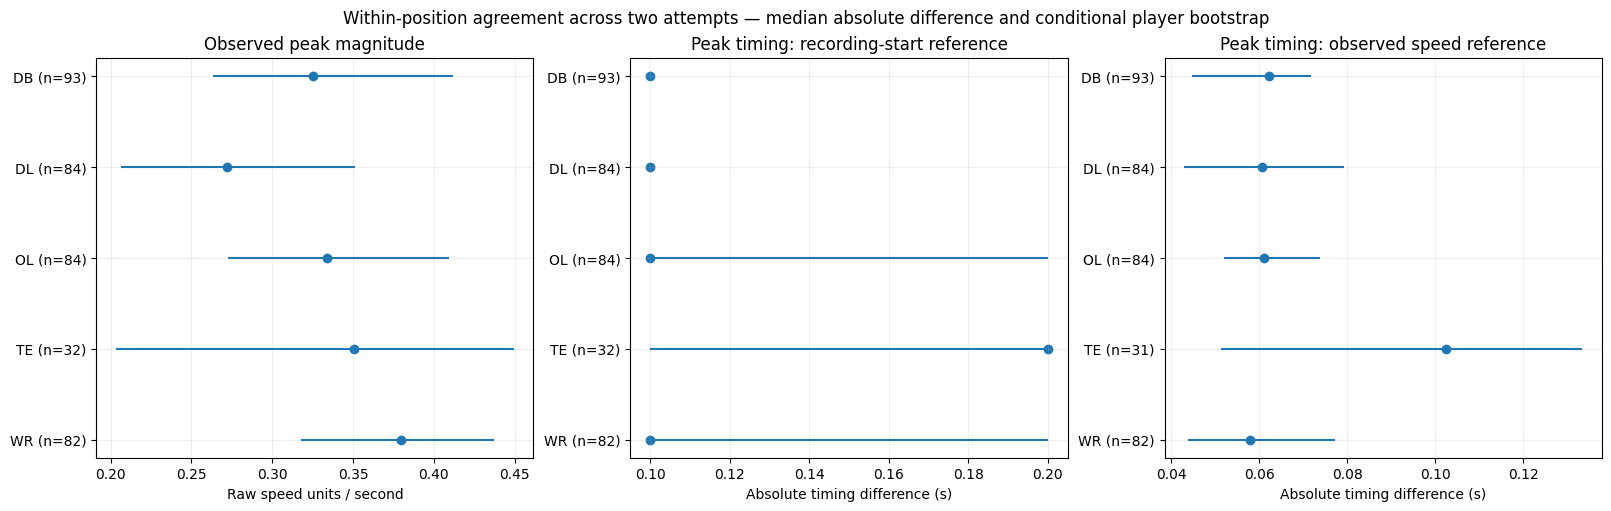

Year-specific timing check — observed speed-reference, 7-frame method:


,combine_position,draft_year,paired_players,pearson,spearman,median_absolute_difference
14,DB,2023,30,0.2066,0.2792,0.0407
52,DB,2024,34,0.5493,0.5053,0.0678
90,DB,2025,29,0.1728,0.2660,0.0716
128,DL,2023,29,0.4528,0.4118,0.0576
166,DL,2024,26,0.5677,0.6048,0.0679
204,DL,2025,29,0.5829,0.5783,0.0581
242,OL,2023,26,0.2083,0.2670,0.0512
280,OL,2024,33,0.4926,0.5124,0.0713
318,OL,2025,25,0.4226,0.4777,0.0630
356,TE,2023,9,0.3412,0.3833,0.1168


In [4]:
plot_specs=[("peak_magnitude","Observed peak magnitude","Raw speed units / second"),
            ("peak_time_recording_start_s","Peak timing: recording-start reference","Absolute timing difference (s)"),
            ("peak_time_speed3_reference_s","Peak timing: observed speed reference","Absolute timing difference (s)")]

fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
positions=sorted(roster["combine_position"].unique())

for ax,(feature,title,xlabel) in zip(axes,plot_specs):
    table=primary_summary.loc[primary_summary["feature"].eq(feature)].set_index("combine_position").reindex(positions)
    y=np.arange(len(positions))
    ax.hlines(y,table["conditional_median_ad_p025"],table["conditional_median_ad_p975"],color="tab:blue")
    ax.scatter(table["median_absolute_difference"],y,color="tab:blue")
    labels=[f"{position} (n={int(n) if pd.notna(n) else 0})" for position,n in zip(positions,table["paired_players"])]
    ax.set(yticks=y,yticklabels=labels,title=title,xlabel=xlabel)
    ax.invert_yaxis();ax.grid(alpha=.2)

fig.suptitle("Within-position agreement across two attempts — median absolute difference and conditional player bootstrap")
plt.show()

print("Year-specific timing check — observed speed-reference, 7-frame method:")

display(year_repeatability.loc[
    year_repeatability["feature"].eq("peak_time_speed3_reference_s")
    &year_repeatability["method"].eq("7-frame")&year_repeatability["scope"].eq("All measured pairs"),
    ["combine_position","draft_year","paired_players","pearson","spearman","median_absolute_difference"]
].round(4))


## E. Audit differences among players with the exact same official 40

Group players by Combine position and the published hundredth-second time. Average only available measurements while retaining attempt counts and boundary flags. Keep single-recording players identifiable. Do not require matching 10-yard splits, NFL opportunities, or two attempts to appear in this descriptive audit.

Report both all-year and same-year groups. The range across player means is a selected descriptive spread, not a significance test, a causal explanation of the 40, or an independent sample of matched pairs. A player's published time is not mapped to each individual recorded attempt. Measurement variability and year effects can contribute to these observed differences.


In [5]:
player_features,exact_time_groups=validate_profiles.exact_time_group_spread(feature_values)

_,same_year_groups=validate_profiles.exact_time_group_spread(feature_values,within_year=True)

print("Same published time: 7-frame observed timing relative to the speed reference")

show=exact_time_groups.loc[exact_time_groups["feature"].eq("peak_time_speed3_reference_s")
                          &exact_time_groups["method"].eq("7-frame")].copy()

show["official_forty_s"]=show["official_forty_hundredths"]/100

columns=["combine_position","official_forty_s","players","draft_years","range_of_player_means",
         "players_with_one_measured_attempt","players_with_boundary_peak"]

display(show.sort_values(["combine_position","official_forty_s"])[columns].round(4))
print("Exact-time groups preserve all years in the main table and provide a separate same-year table.")

Same published time: 7-frame observed timing relative to the speed reference


,combine_position,official_forty_s,players,draft_years,range_of_player_means,players_with_one_measured_attempt,players_with_boundary_peak
7,DB,4.33,2,2,0.5294,0,0
35,DB,4.36,4,3,0.1345,1,0
64,DB,4.38,3,1,0.3791,2,0
93,DB,4.39,2,2,0.0857,0,0
121,DB,4.41,3,2,0.2397,0,1
...,...,...,...,...,...,...,...
2774,WR,4.57,6,3,0.2234,2,0
2803,WR,4.58,2,2,0.1461,0,0
2831,WR,4.59,2,2,0.0388,0,0
2860,WR,4.6,2,1,0.1089,0,0


Exact-time groups preserve all years in the main table and provide a separate same-year table.


## F. Keep NFL validation scope explicit

Notebook 04 currently exports a **WR-only route pilot**, so its target cannot be reused as the universal outcome for DB, DL, OL, or TE. No new all-position NFL model is fitted in this notebook. The archived WR model's null finding remains specific to its interval feature, route outcome, and eligibility rules.

Next, broaden Notebook 04: specify a suitable movement context, time reference, opportunity rule, and outcome for each position, then audit their coverage. That handoff must precede corresponding held-out NFL model comparisons. The main Combine comparison remains available for all tracked players regardless of NFL eligibility. Updating this notebook does not establish the missing NFL linkage.


In [6]:
legacy_nfl_manifest=ROOT/"outputs/nfl_translation/manifest.json"

nfl_readiness=pd.DataFrame({
    "combine_position":sorted(roster["combine_position"].unique()),
    "combine_players":[int(roster["combine_position"].eq(p).sum()) for p in sorted(roster["combine_position"].unique())],
    "new_position_specific_nfl_test":"Not run — broaden Notebook 04 outcome definitions and coverage first",
})

print("Existing WR pilot files present:",legacy_nfl_manifest.is_file())
display(nfl_readiness)
print("No all-position NFL predictive-improvement claim is made here.")

Existing WR pilot files present: True


,combine_position,combine_players,new_position_specific_nfl_test
0,DB,102,Not run — broaden Notebook 04 outcome definiti...
1,DL,93,Not run — broaden Notebook 04 outcome definiti...
2,OL,95,Not run — broaden Notebook 04 outcome definiti...
3,TE,34,Not run — broaden Notebook 04 outcome definiti...
4,WR,94,Not run — broaden Notebook 04 outcome definiti...


No all-position NFL predictive-improvement claim is made here.


## G. Save the validation evidence

Write to `outputs/all_position_validation/`. Keep all-player source features, unavailable-measurement statuses, paired-player rows, all method/position summaries, year sensitivity, exact-time group audits, and the NFL readiness status. The earlier `outputs/validation/` model results are left unchanged.

A small paired difference alone does not prove validity, and a large between-player spread alone does not prove football value. Report observed peak timing with its stated reference and boundary status. Revisit physical units and launch coverage before stronger physical or causal interpretations.


In [7]:
exports={"attempt_feature_values.csv":feature_values,"timing_reference_audit.csv":references,
         "feature_coverage.csv":feature_coverage,"paired_feature_values.csv":paired_features,
         "within_position_repeatability.csv":repeatability,"within_position_year_repeatability.csv":year_repeatability,
         "player_feature_summaries.csv":player_features,"exact_official_time_groups.csv":exact_time_groups,
         "same_year_exact_official_time_groups.csv":same_year_groups,"nfl_validation_readiness.csv":nfl_readiness}

validation_manifest={"schema_version":1,"created_utc":datetime.now(timezone.utc).isoformat(),
    "scope":"All Combine positions; observed profile repeatability and same-official-time descriptive audit",
    "source_profile_manifest_sha256":hashlib.sha256((PROFILES/"manifest.json").read_bytes()).hexdigest(),
    "source_prepared_manifest_sha256":hashlib.sha256((PREPARED/"manifest.json").read_bytes()).hexdigest(),
    "player_count":len(roster),"bootstrap_unit":"Paired players, stratified by observed draft year within position",
    "bootstrap_replicates":BOOTSTRAPS,
    "timing_references":["First recorded frame, not physical launch","Observed sustained 3-unit speed crossing, not physical launch"],
    "nfl_stage":"Not run; Notebook 04 remains a separate WR outcome pilot",
    "limitations":["Physical speed units unverified","Launch and full-finish coverage unverified",
        "Repeatability reflects both execution and measurement differences",
        "Bootstrap intervals are conditional on observed paired measurements",
        "Published player-level 40 is not linked to every recorded attempt",
        "Cross-year processing can affect comparisons","No new NFL linkage established"],"files":{}}

for name,table in exports.items():
    path=OUTPUT/name;table.to_csv(path,index=False)
    validation_manifest["files"][name]={"rows":len(table),"sha256":hashlib.sha256(path.read_bytes()).hexdigest()}
(OUTPUT/"manifest.json").write_text(json.dumps(validation_manifest,indent=2)+"\n")

print("Saved all-position validation:",OUTPUT)
print("Comparison roster retained:",len(roster),"players; single-recording players remain eligible for display.")
print("The archived WR model/results were not regenerated.")


Saved all-position validation: /Users/hunterclark/Documents/New project/nfl-big-data-bowl-2027/outputs/all_position_validation
Comparison roster retained: 418 players; single-recording players remain eligible for display.
The archived WR model/results were not regenerated.
